In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [30]:
df = pd.read_csv(r"/Users/satwik/Downloads/data.csv")
print("Data loaded successfully!!!")
print("Dataset shape:", df.shape)

Data loaded successfully!!!
Dataset shape: (569, 33)


In [31]:
# Remove unwanted columns
df.columns = df.columns.str.strip()

df = df.drop(
    columns=["id", "Unnamed: 32"],
    errors="ignore"
)

# Convert diagnosis into numerical values
# M = Malignant (1)
# B = Benign (0)

df["diagnosis"] = df["diagnosis"].map({
    "M": 1,
    "B": 0
})

# Check for missing target values
df = df.dropna(subset=["diagnosis"])

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
print(df.head())

print("\nClass balance (1 = Malignant, 0 = Benign):")
print(df["diagnosis"].value_counts())

Dataset shape: (569, 31)

First 5 rows:
   diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0          1        17.99         10.38          122.80     1001.0   
1          1        20.57         17.77          132.90     1326.0   
2          1        19.69         21.25          130.00     1203.0   
3          1        11.42         20.38           77.58      386.1   
4          1        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   symmetry_mean  ...  radius_worst  texture_worst  perimeter_worst  \
0    

In [32]:
# Separate input features and output target

X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (455, 30)
Testing data shape: (114, 30)


In [33]:
# Replace infinite values with NaN

X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

# Create ML pipeline

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000))
])

# Train the model

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [34]:
# Predict test data

y_pred = model.predict(X_test)

# Calculate prediction probabilities

y_prob = model.predict_proba(X_test)[:, 1]

print("Predictions completed successfully!")

Predictions completed successfully!



Confusion Matrix:

[[71  1]
 [ 3 39]]

TN = 71
FP = 1
FN = 3
TP = 39

Accuracy  : 0.9649
Precision : 0.975
Recall    : 0.9286
F1-score  : 0.9512
ROC-AUC   : 0.996

Full Classification Report:

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



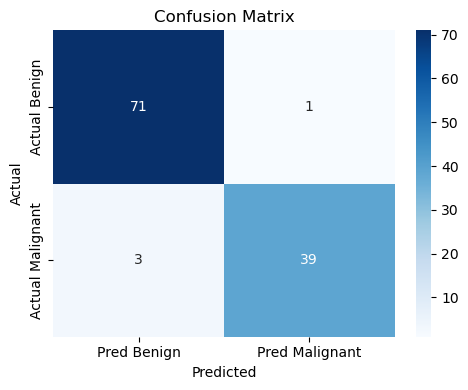

In [35]:
# Calculate confusion matrix

cm = confusion_matrix(y_test, y_pred)

tn, fp, fn, tp = cm.ravel()

print("\nConfusion Matrix:\n")
print(cm)

print(f"\nTN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")

# Calculate evaluation metrics

print("\nAccuracy  :", round(accuracy_score(y_test, y_pred), 4))

print("Precision :", round(precision_score(y_test, y_pred), 4))

print("Recall    :", round(recall_score(y_test, y_pred), 4))

print("F1-score  :", round(f1_score(y_test, y_pred), 4))

print("ROC-AUC   :", round(roc_auc_score(y_test, y_prob), 4))

# Classification report

print("\nFull Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Benign", "Malignant"]
    )
)

# Plot confusion matrix

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred Benign", "Pred Malignant"],
    yticklabels=["Actual Benign", "Actual Malignant"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()

plt.savefig("confusion_matrix.png")

plt.show()

In [36]:
# Extract feature coefficients from Logistic Regression

coef_df = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": model.named_steps["logreg"].coef_[0]
}).sort_values(
    "coefficient",
    ascending=False
)

# Top 5 features pushing towards Malignant

print("\nTop 5 features pushing towards MALIGNANT:\n")

print(coef_df.head(5))

# Top 5 features pushing towards Benign

print("\nTop 5 features pushing towards BENIGN:\n")

print(coef_df.tail(5))


Top 5 features pushing towards MALIGNANT:

                feature  coefficient
21        texture_worst     1.434093
10            radius_se     1.233325
28       symmetry_worst     1.061264
7   concave points_mean     0.952813
26      concavity_worst     0.911406

Top 5 features pushing towards BENIGN:

                 feature  coefficient
18           symmetry_se    -0.330658
11            texture_se    -0.407611
5       compactness_mean    -0.439546
19  fractal_dimension_se    -0.593876
15        compactness_se    -0.906925


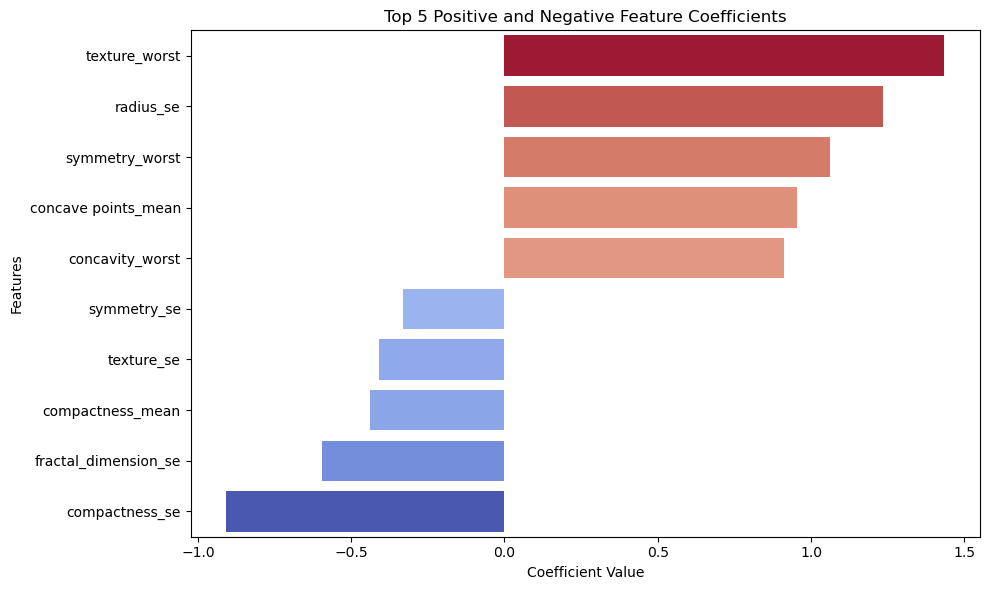

In [37]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=pd.concat([
        coef_df.head(5),
        coef_df.tail(5)
    ]),
    x="coefficient",
    y="feature",
    hue="coefficient",
    palette="coolwarm",
    legend=False
)

plt.title("Top 5 Positive and Negative Feature Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [39]:
# ----------------------------------------------------------------------
# 7. THRESHOLD EXPERIMENT (precision / recall trade-off)
# ----------------------------------------------------------------------

print("\nThreshold  Precision  Recall    F1")
for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
    pred_t = (y_prob >= t).astype(int)
    print(f"{t:.1f}          "
          f"{precision_score(y_test, pred_t, zero_division=0):.3f}     "
          f"{recall_score(y_test, pred_t):.3f}     "
          f"{f1_score(y_test, pred_t):.3f}")


Threshold  Precision  Recall    F1
0.1          0.891     0.976     0.932
0.3          0.976     0.976     0.976
0.5          0.975     0.929     0.951
0.7          1.000     0.905     0.950
0.9          1.000     0.786     0.880
